# Assignment 3: Spectral Clustering and K-medoids vs K-means

## Introduction
In this assignment I compare two advanced clustering methods from Lesson 3 with K-means, using synthetic (computer-generated) datasets.

- Spectral clustering builds a similarity graph of the points and can find clusters with curved, non-round shapes.
- K-medoids works like K-means, but each cluster centre must be a real data point (a medoid), and it can use any distance metric.

Because the datasets are synthetic, I know the true groups, so I can check which method gets them right.

My steps:
- Import libraries and set a random seed
- Create a dataset with two curved (sine-wave) clusters, plot it, and compare Spectral Clustering with K-means
- Create a second dataset with several round clusters and compare K-means with K-medoids
- Test how the distance metric and the parameter p change the K-medoids results
- Answer the questions

## 1. Import Libraries and Set Random Seed

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import SpectralClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.spatial.distance import pdist, cdist, squareform

np.random.seed(42)
sns.set_theme(style="whitegrid")

## 2. Dataset 1 – Two Sine-Wave Clusters

In [2]:
nb_samples = 1000

X0 = np.expand_dims(np.linspace(-2 * np.pi, 2 * np.pi, nb_samples), axis=1)
Y0 = -2.0 - np.cos(2.0 * X0) + np.random.uniform(0.0, 2.0, size=(nb_samples, 1))
Y1 = 2.0 - np.cos(2.0 * X0) + np.random.uniform(0.0, 2.0, size=(nb_samples, 1))

data_0 = np.concatenate([X0, Y0], axis=1)
data_1 = np.concatenate([X0, Y1], axis=1)
data = np.concatenate([data_0, data_1], axis=0)
true_labels_1 = np.array([0] * nb_samples + [1] * nb_samples)

print("Dataset 1 shape:", data.shape)

Dataset 1 shape: (2000, 2)


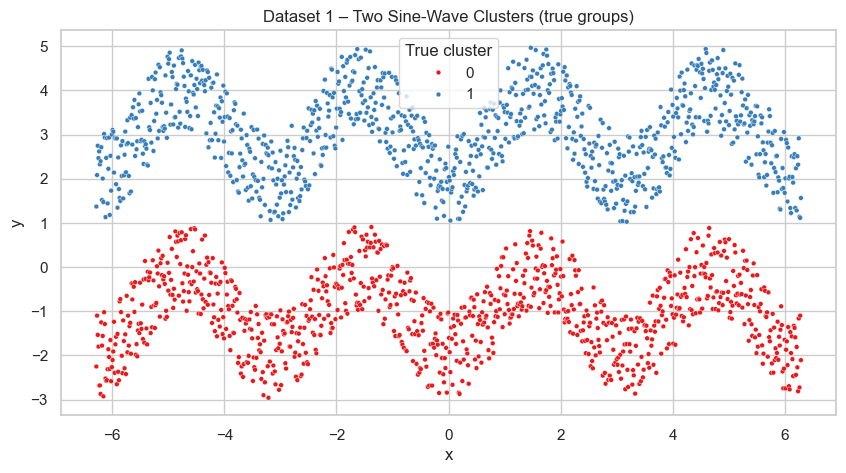

In [3]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x=data[:, 0], y=data[:, 1], hue=true_labels_1, palette="Set1", s=12)
plt.title("Dataset 1 – Two Sine-Wave Clusters (true groups)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend(title="True cluster")
plt.show()

### Interpretation – Dataset 1
- The dataset has 2,000 points with 2 features (x and y): 1,000 points in a lower sine-wave band and 1,000 points in an upper sine-wave band.
- Each band is curved, not round, and the random noise makes each wave about 2 units thick.
- The two bands never overlap, but they come very close at the peaks of the waves, where the gap is very narrow.
- The data is much wider (x from about -6.3 to 6.3) than it is tall (y from about -3 to 5).
- Because the clusters are long and curved instead of round, this is a non-convex dataset. K-means assumes round (convex) clusters, so I expect it to struggle here, while Spectral Clustering should be able to follow the curved shapes.

## 3. Spectral Clustering vs K-means on Dataset 1

In [4]:
km_1 = KMeans(n_clusters=2, n_init=10, random_state=42)
km_labels_1 = km_1.fit_predict(data)

sc_1 = SpectralClustering(n_clusters=2, affinity="rbf", gamma=2.0, random_state=42)
sc_labels_1 = sc_1.fit_predict(data)

print(f"ARI – K-means: {adjusted_rand_score(true_labels_1, km_labels_1):.4f}")
print(f"ARI – Spectral: {adjusted_rand_score(true_labels_1, sc_labels_1):.4f}")
print(f"Silhouette – K-means: {silhouette_score(data, km_labels_1):.4f}")
print(f"Silhouette – Spectral: {silhouette_score(data, sc_labels_1):.4f}")

ARI – K-means: -0.0005
ARI – Spectral: 1.0000
Silhouette – K-means: 0.4549
Silhouette – Spectral: 0.2786


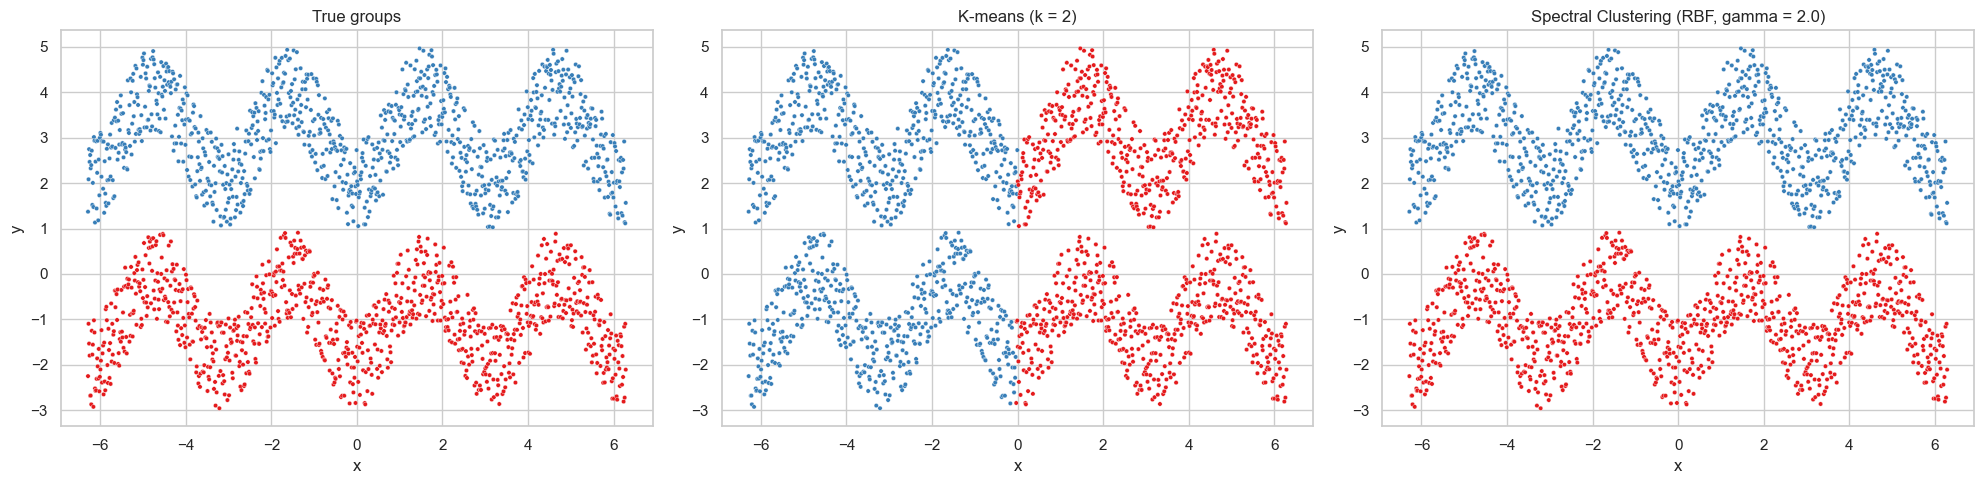

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
plots = [(true_labels_1, "True groups"),
         (km_labels_1, "K-means (k = 2)"),
         (sc_labels_1, "Spectral Clustering (RBF, gamma = 2.0)")]
for ax, (labels, title) in zip(axes, plots):
    sns.scatterplot(x=data[:, 0], y=data[:, 1], hue=labels, palette="Set1", s=10, ax=ax, legend=False)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

### Interpretation – Spectral Clustering vs K-means (Dataset 1)
- K-means did not find the two waves. It cut the data straight down the middle at about x = 0 and grouped the left half of both waves together and the right half of both waves together. Its ARI (Adjusted Rand Index) is -0.0005, which means its clusters match the true groups no better than random.
- Spectral Clustering found both waves perfectly, with an ARI of 1.0000. Every point was assigned to the correct wave.
- K-means made this mistake because it assumes clusters are round and tries to minimize the distance from each point to its centre. Since the data is much wider than it is tall, splitting it into a left half and a right half gives two compact groups with a smaller total distance than following the curved waves.
- Spectral Clustering works differently. It first builds a similarity graph where only close neighbours are strongly connected (RBF with gamma = 2.0). Points along the same wave are linked to each other like a chain, while the two waves are only weakly linked across the gap. It then clusters in a new space based on this graph, where the two waves become easy to separate.
- The silhouette score is misleading here. K-means scores higher (0.4549) than Spectral (0.2786) even though K-means is wrong. The silhouette score also favours round, compact clusters, so it is not a good measure for curved, non-convex clusters. Because I know the true labels, ARI is the better measure in this case.

## 4. Dataset 2 – Multiple Round Clusters

## 5. K-means on Dataset 2

In [6]:
X2, true_labels_2 = make_blobs(n_samples=1000, n_features=2, centers=3,
                               cluster_std=1.5, random_state=42)
print("Dataset 2 shape:", X2.shape)
print("True cluster sizes:", np.bincount(true_labels_2))

Dataset 2 shape: (1000, 2)
True cluster sizes: [334 333 333]


In [7]:
km_2 = KMeans(n_clusters=3, n_init=10, random_state=42)
km_labels_2 = km_2.fit_predict(X2)
km_centers_2 = km_2.cluster_centers_

print(f"\nK-means ARI: {adjusted_rand_score(true_labels_2, km_labels_2):.4f}")
print(f"K-means silhouette: {silhouette_score(X2, km_labels_2):.4f}")
print("K-means centroids:\n", km_centers_2.round(3))


K-means ARI: 0.9970
K-means silhouette: 0.7650
K-means centroids:
 [[-2.521  8.988]
 [-6.86  -6.738]
 [ 4.785  2.087]]


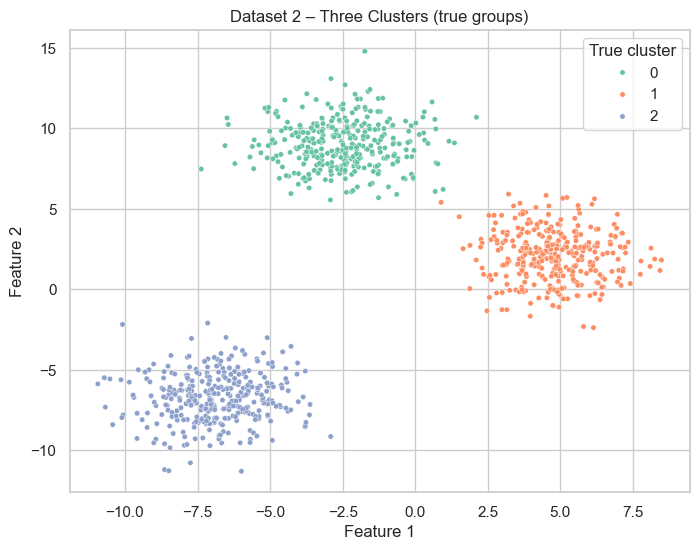

In [8]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=true_labels_2, palette="Set2", s=15)
plt.title("Dataset 2 – Three Clusters (true groups)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend(title="True cluster")
plt.show()

### Interpretation – Dataset 2 and K-means
- Dataset 2 has 1,000 points with 2 features in 3 round clusters of about the same size (334, 333 and 333 points). The clusters are clearly apart from each other, with only a few points at the edges between the top (green) and right (orange) groups.
- K-means found the 3 clusters almost perfectly, with an ARI of 0.9970. Only one or two edge points were assigned to the wrong cluster.
- The silhouette score is high (0.7650), which means the clusters are compact and well separated.
- This is the type of data K-means is designed for: round, similar-sized clusters. Its centroids are at about (-2.52, 8.99), (-6.86, -6.74) and (4.79, 2.09), right in the middle of each blob. These centroids are averages, so they are not actual data points.

## 6. K-medoids on Dataset 2

In [9]:
def kmedoids(X, n_clusters, metric="minkowski", p=2, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    medoids = X[rng.choice(len(X), n_clusters, replace=False)].copy()

    for iteration in range(1, max_iter + 1):
        labels = np.argmin(cdist(X, medoids, metric=metric, p=p), axis=1)
        new_medoids = medoids.copy()
        for i in range(n_clusters):
            members = X[labels == i]
            if len(members) == 0:
                continue
            D = squareform(pdist(members, metric=metric, p=p))
            new_medoids[i] = members[np.argmin(D.sum(axis=1))]
        if np.allclose(new_medoids, medoids):
            break
        medoids = new_medoids

    labels = np.argmin(cdist(X, medoids, metric=metric, p=p), axis=1)
    return labels, medoids, iteration


kmed_labels_2, medoids_2, n_iter = kmedoids(X2, n_clusters=3, metric="minkowski", p=2)

print(f"K-medoids converged in {n_iter} iterations")
print(f"K-medoids ARI: {adjusted_rand_score(true_labels_2, kmed_labels_2):.4f}")
print(f"K-medoids silhouette: {silhouette_score(X2, kmed_labels_2):.4f}")
print("Medoids:\n", medoids_2.round(3))
print("Are the medoids real data points?",
      all((X2 == m).all(axis=1).any() for m in medoids_2))

K-medoids converged in 3 iterations
K-medoids ARI: 0.9970
K-medoids silhouette: 0.7650
Medoids:
 [[ 4.697  2.153]
 [-2.488  8.978]
 [-7.028 -6.852]]
Are the medoids real data points? True


### Interpretation – K-medoids (p = 2, Euclidean)
- My K-medoids converged in only 3 iterations, so the medoids stopped changing very quickly.
- It got exactly the same scores as K-means: ARI = 0.9970 and silhouette = 0.7650. This means both methods put every point into the same cluster.
- The medoids are at (4.70, 2.15), (-2.49, 8.98) and (-7.03, -6.85). They are very close to the K-means centroids (only about 0.03 to 0.20 units away), because on clean, round clusters the most central real point is almost the same as the average.
- The check confirmed that all 3 medoids are real data points from the dataset, unlike K-means centroids, which are calculated averages.
- On this clean dataset, K-medoids gives no advantage over K-means, but it also loses nothing. Its benefits show up when there are outliers or when a different distance metric is needed, which I test next.

## 7. Visualizing Clustering Results for Dataset 2

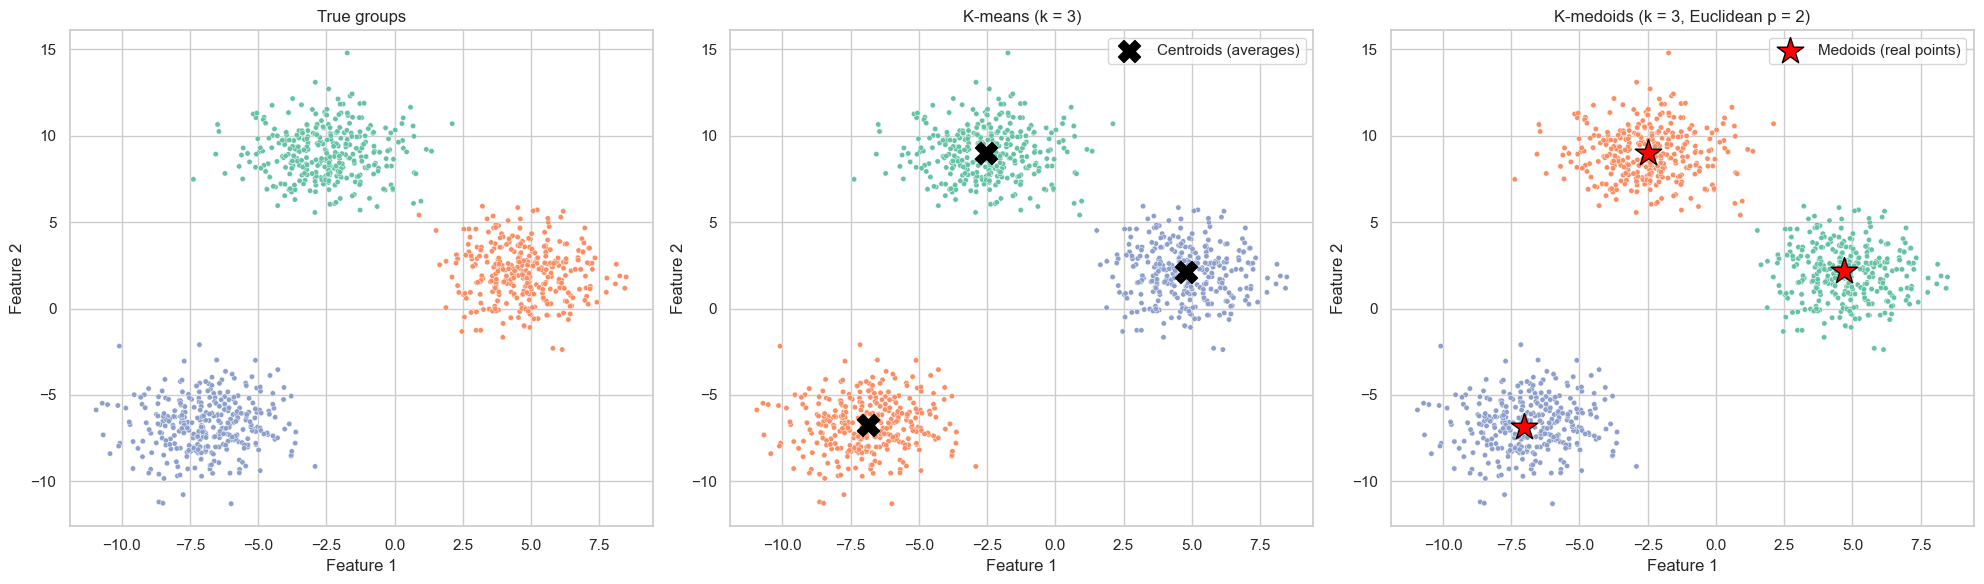

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=true_labels_2, palette="Set2", s=15, ax=axes[0], legend=False)
axes[0].set_title("True groups")

sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=km_labels_2, palette="Set2", s=15, ax=axes[1], legend=False)
axes[1].scatter(km_centers_2[:, 0], km_centers_2[:, 1], c="black", marker="X", s=250, label="Centroids (averages)")
axes[1].set_title("K-means (k = 3)")
axes[1].legend()

sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=kmed_labels_2, palette="Set2", s=15, ax=axes[2], legend=False)
axes[2].scatter(medoids_2[:, 0], medoids_2[:, 1], c="red", marker="*", s=400, edgecolor="black", label="Medoids (real points)")
axes[2].set_title("K-medoids (k = 3, Euclidean p = 2)")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

### Interpretation – Clustering Results for Dataset 2
- Both K-means and K-medoids found the same 3 groups as the true labels. The colours are different in each plot only because cluster numbers are random labels. The grouping of the points is the same, which is why both methods have the same ARI (0.9970).
- The K-means centroids (black X) and the K-medoids medoids (red stars) are both in the middle of each cluster and almost in the same places.
- The difference is what the centres are. The K-means centroids are calculated averages, while the medoids are actual data points from the dataset. On round, clean clusters like these, both give almost the same result.

### 7.1 Effect of the Minkowski Parameter p on K-medoids

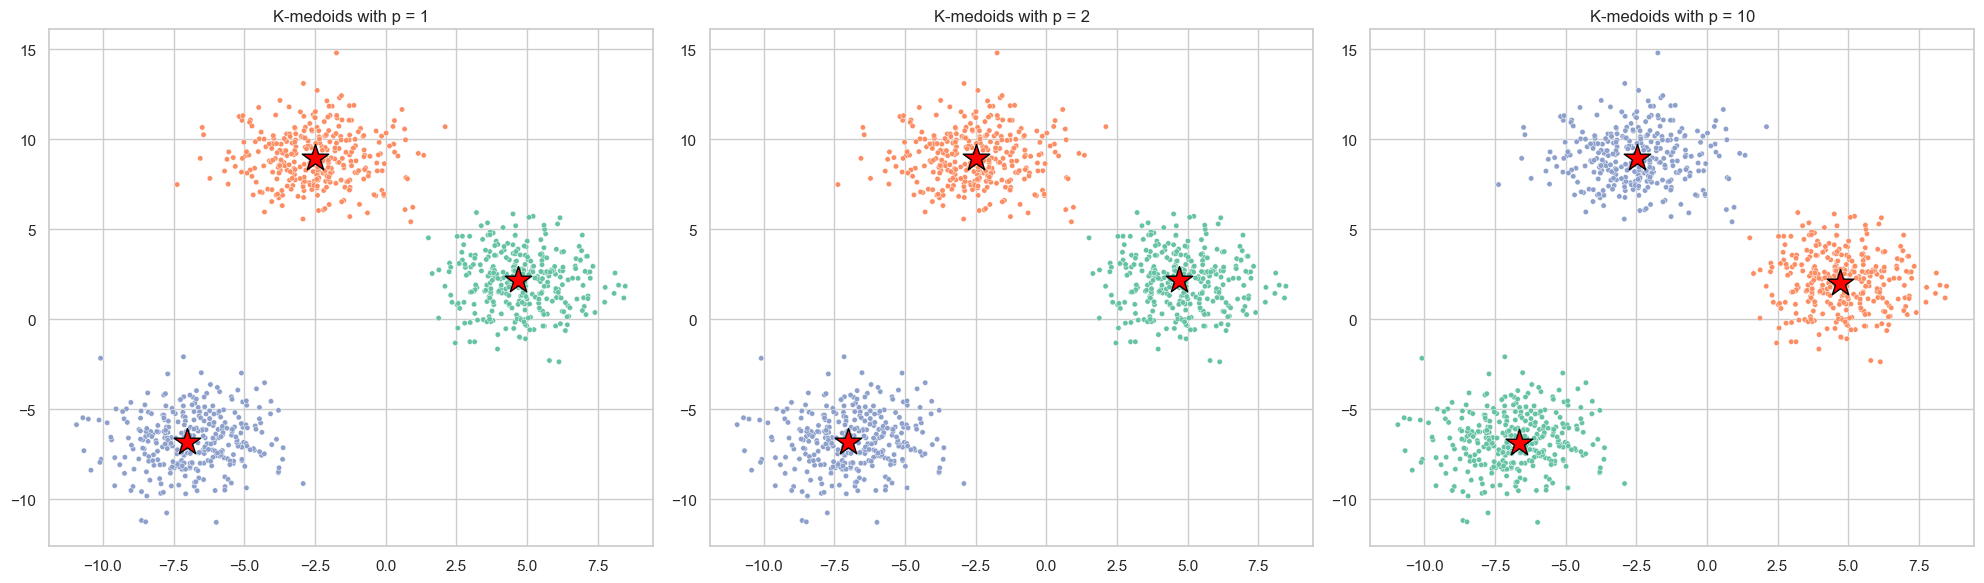

 p           distance  iterations  ARI vs truth  ARI vs p=2 result  silhouette                                       medoids
 1          Manhattan           3         0.997                1.0       0.765  [[4.7, 2.15], [-2.49, 8.98], [-7.03, -6.85]]
 2          Euclidean           3         0.997                1.0       0.765  [[4.7, 2.15], [-2.49, 8.98], [-7.03, -6.85]]
10 close to Chebyshev           7         0.997                1.0       0.765 [[-6.64, -6.88], [4.71, 2.03], [-2.49, 8.98]]


In [11]:
p_values = [1, 2, 10]
p_results = []

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, p in zip(axes, p_values):
    labels_p, medoids_p, iters_p = kmedoids(X2, n_clusters=3, metric="minkowski", p=p)
    p_results.append({
        "p": p,
        "distance": {1: "Manhattan", 2: "Euclidean", 10: "close to Chebyshev"}[p],
        "iterations": iters_p,
        "ARI vs truth": round(adjusted_rand_score(true_labels_2, labels_p), 4),
        "ARI vs p=2 result": round(adjusted_rand_score(kmed_labels_2, labels_p), 4),
        "silhouette": round(silhouette_score(X2, labels_p), 4),
        "medoids": np.round(medoids_p, 2).tolist(),
    })
    sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=labels_p, palette="Set2", s=15, ax=ax, legend=False)
    ax.scatter(medoids_p[:, 0], medoids_p[:, 1], c="red", marker="*", s=400, edgecolor="black")
    ax.set_title(f"K-medoids with p = {p}")
plt.tight_layout()
plt.show()

print(pd.DataFrame(p_results).to_string(index=False))

### Interpretation – Effect of the Metric Parameter p
I ran K-medoids with the Minkowski distance using p = 1 (Manhattan), p = 2 (Euclidean) and p = 10 (close to Chebyshev), keeping the same random starting points so only the metric changed.
- All three runs put the points into exactly the same clusters. The ARI against the true groups is 0.997 for every p, and the ARI against the p = 2 result is 1.0, so not a single point changed cluster. The silhouette score also stayed at 0.765.
- p = 1 picked exactly the same medoids as p = 2.
- p = 10 picked different medoids for 2 of the 3 clusters (for example, the bottom-left medoid moved from (-7.03, -6.85) to (-6.64, -6.88)). With a high p, the distance only depends on the biggest difference in x or y and mostly ignores the smaller one, so a different point becomes the most central one.
- p = 10 also needed 7 iterations instead of 3. Because it ignores part of the information, the distances are less precise and the medoids take longer to settle.
- On this dataset the clusters are so well separated that the metric does not change the final groups. On overlapping or stretched clusters, a different p could move points between clusters. As Lesson 2 explains, a small p (1 or 2) is usually better because it uses the differences in all features, while a large p only looks at the single biggest one.

### 7.2 Outlier Test – K-means vs K-medoids

In [12]:
rng = np.random.default_rng(7)
outliers = np.column_stack([rng.uniform(14, 16, 15), rng.uniform(0, 4, 15)])
X2_out = np.vstack([X2, outliers])
print("Data with outliers:", X2_out.shape)

km_out = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X2_out)
kmed_out_labels, medoids_out, _ = kmedoids(X2_out, n_clusters=3, p=2)

right_km_before = km_centers_2[np.argmax(km_centers_2[:, 0])]
right_km_after = km_out.cluster_centers_[np.argmax(km_out.cluster_centers_[:, 0])]
right_med_before = medoids_2[np.argmax(medoids_2[:, 0])]
right_med_after = medoids_out[np.argmax(medoids_out[:, 0])]

print("Right cluster – K-means centroid:", right_km_before.round(3), "->", right_km_after.round(3),
      f"| moved {np.linalg.norm(right_km_after - right_km_before):.3f}")
print("Right cluster – K-medoid:       ", right_med_before.round(3), "->", right_med_after.round(3),
      f"| moved {np.linalg.norm(right_med_after - right_med_before):.3f}")
print(f"\nARI on the original 1,000 points – K-means: {adjusted_rand_score(true_labels_2, km_out.labels_[:1000]):.4f}"
      f" | K-medoids: {adjusted_rand_score(true_labels_2, kmed_out_labels[:1000]):.4f}")

Data with outliers: (1015, 2)
Right cluster – K-means centroid: [4.785 2.087] -> [5.227 2.09 ] | moved 0.442
Right cluster – K-medoid:        [4.697 2.153] -> [4.811 2.199] | moved 0.123

ARI on the original 1,000 points – K-means: 0.9970 | K-medoids: 0.9970


### Interpretation – Outlier Test
- I added 15 outliers (about 1.5% of the data) far to the right of the right-hand cluster, around x = 14 to 16.
- The K-means centroid of that cluster moved from (4.785, 2.087) to (5.227, 2.090), a shift of 0.442 units toward the outliers. This happens because a centroid is the average of all points in the cluster, so a few extreme values pull it toward them.
- The K-medoid moved only 0.123 units, from (4.697, 2.153) to (4.811, 2.199). That is about 3.6 times less than the centroid. A medoid must be a real point that is closest to all the others, so a few far-away points cannot drag it out of the main group. It works like a median instead of a mean.
- The cluster assignments of the original 1,000 points did not change (ARI = 0.9970 for both methods), because the clusters are far apart. The outliers affected the position of the centre, not which points belong together.
- This shows the main advantage of K-medoids: its centres are much more robust to outliers than K-means centroids.

### 1. How do the clusters formed by Spectral Clustering compare to those formed by K-means?
On Dataset 1 (two sine waves), Spectral Clustering found both waves perfectly (ARI = 1.0000), while K-means failed completely (ARI = -0.0005). K-means ignored the wave shapes and cut the data into a left half and a right half at about x = 0, so each of its clusters contained half of each wave. Interestingly, the silhouette score rated K-means higher (0.4549 vs 0.2786), even though K-means was wrong. This shows that the silhouette score, like K-means, favours round clusters and can be misleading for curved shapes.

### 2. Why might Spectral Clustering perform better on the first dataset than K-means?
K-means assumes clusters are round (convex) and assigns each point to the nearest centroid. Since the data is much wider than it is tall, splitting it into left and right halves gives a smaller total distance than following the curves, so K-means chooses the wrong split. Spectral Clustering does not look at distance to a centre. It builds a similarity graph where only nearby points are strongly connected (RBF with gamma = 2.0), so points along each wave form a connected chain, while the two waves are only weakly linked across the gap. Using the eigenvectors of the graph Laplacian, it moves the data into a new space where the two waves become easy to separate, and then runs K-means there. This lets it handle non-convex shapes that K-means cannot.

### 3. What are the advantages and disadvantages of using K-medoids over K-means?
Advantages:
- It is more robust to outliers. In my test, 15 outliers moved the K-means centroid 0.442 units but the medoid only 0.123 units (about 3.6 times less).
- The cluster centres are real data points, which are easier to explain (for example, a real customer can represent a segment).
- It can use any distance metric (Manhattan, Euclidean, or others), not only Euclidean distance.

Disadvantages:
- It is slower, because it has to calculate distances between every pair of points inside each cluster. This becomes very expensive for large datasets.
- Like K-means, it still needs the number of clusters (k) in advance.
- Like K-means, it works best on round clusters and cannot handle curved shapes like the sine waves.
- It is not built into scikit-learn, so I had to write it myself.
On my clean Dataset 2, both methods gave exactly the same clusters (ARI = 0.9970 and silhouette = 0.7650), so K-medoids' advantages only show up with outliers or when a different metric is needed.

### 4. How does the choice of metric and parameter p affect the results of K-medoids clustering?
The Minkowski distance changes with p: p = 1 is Manhattan distance, p = 2 is Euclidean distance, and a large p (like 10) gets close to Chebyshev distance, where only the biggest difference between two points matters. In my test, all three values gave exactly the same cluster assignments (ARI = 0.997 against the truth and 1.0 against the p = 2 result) because the clusters are well separated. However, p = 10 picked different medoids for 2 of the 3 clusters and needed 7 iterations instead of 3, because it ignores the smaller coordinate difference and judges "central" in a different way. On overlapping or stretched clusters, p could also move points between clusters. A small p (1 or 2) is usually the better choice because it uses the differences in all features, while a large p only uses the single biggest one.

## Conclusion
In this assignment I compared Spectral Clustering and K-medoids with K-means on two synthetic datasets. On the curved sine-wave data, Spectral Clustering was perfect (ARI = 1.0) while K-means failed (ARI = -0.0005), which shows that K-means cannot handle non-convex clusters. On the round blob data, K-means and K-medoids gave exactly the same clusters (ARI = 0.997), the choice of p did not change the groups, and K-medoids proved much more